In [ ]:
#Import Libraries
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.datasets import make_circles

plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['font.size'] = 11

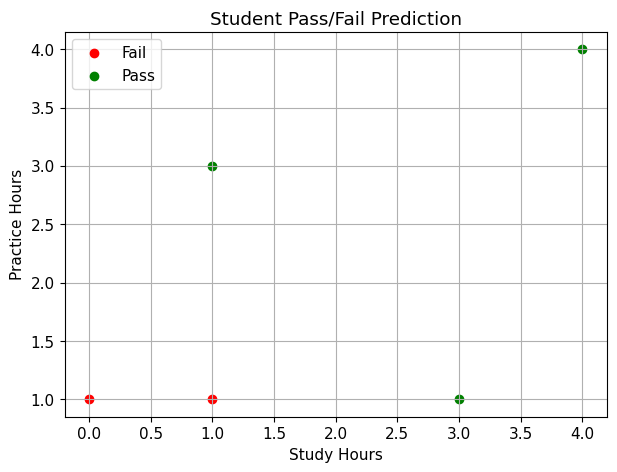

In [ ]:

# Features: Study Hours and Practice Hours
X = np.array([
    [1, 1],  # Student A
    [0, 1],  # Student B
    [3, 1],  # Student C
    [1, 3],  # Student D
    [4, 4]   # Student E
])

# Labels: -1 = Fail, 1 = Pass
y = np.array([-1, -1, 1, 1, 1])
# Student names
names = ['A', 'B', 'C', 'D', 'E']

# Plot the data
plt.scatter(X[y == -1, 0], X[y == -1, 1],
            color="red", label="Fail")

plt.scatter(X[y == 1, 0], X[y == 1, 1],
            color="green", label="Pass")

plt.xlabel("Study Hours")
plt.ylabel("Practice Hours")
plt.title("Student Pass/Fail Prediction")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Equations from the :
# A: w1 + w2 + b = -1
# C: 3w1 + w2 + b =  1
# D: w1 + 3w2 + b =  1

equations = np.array([
    [1, 1, 1],
    [3, 1, 1],
    [1, 3, 1]
])

results = np.array([-1, 1, 1])

w1, w2, b = np.linalg.solve(equations, results)

print("w1 =", w1)
print("w2 =", w2)
print("b  =", b)

print("\nDecision Function:")
print(f"f(x) = {w1}*x1 + {w2}*x2 + ({b})")

w1 = 1.0
w2 = 1.0000000000000002
b  = -3.0

Decision Function:
f(x) = 1.0*x1 + 1.0000000000000002*x2 + (-3.0)


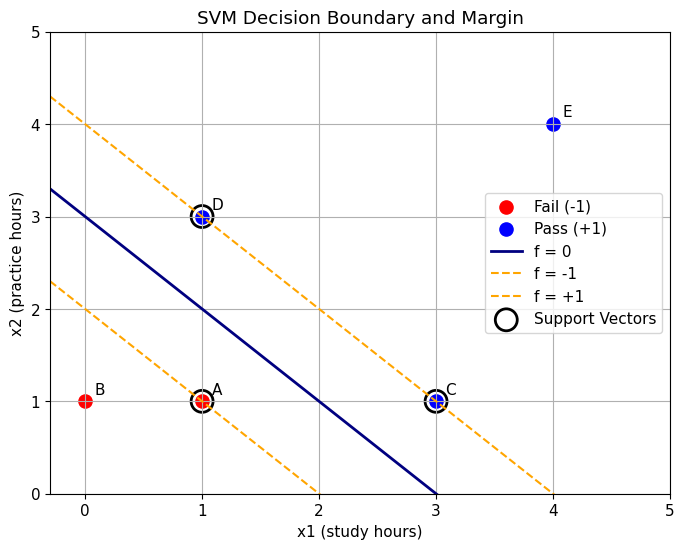

In [ ]:
# Decision Boundary, Margin and Support Vectors
#Calculate decision function
def decision_function(x1, x2):
    return w1*x1 + w2*x2 + b

x1_line = np.linspace(-0.3, 5, 200)

# Decision boundary and margin lines
line_0 = 3 - x1_line
line_minus = 2 - x1_line
line_plus = 4 - x1_line

plt.figure(figsize=(8, 6))

# Students
plt.scatter(X[y == -1, 0], X[y == -1, 1],
            color='red', label='Fail (-1)', s=90)

plt.scatter(X[y == 1, 0], X[y == 1, 1],
            color='blue', label='Pass (+1)', s=90)

for i in range(len(X)):
    plt.text(X[i, 0] + 0.08, X[i, 1] + 0.08, names[i])

# Decision boundary
plt.plot(x1_line, line_0, color='navy',
         linewidth=2, label='f = 0')

# Margins
plt.plot(x1_line, line_minus, '--',
         color='orange', label='f = -1')

plt.plot(x1_line, line_plus, '--',
         color='orange', label='f = +1')

# Highlight support vectors A, C and D
support_indices = [0, 2, 3]

plt.scatter(X[support_indices, 0],
            X[support_indices, 1],
            s=250, facecolors='none',
            edgecolors='black', linewidths=2,
            label='Support Vectors')

plt.xlabel('x1 (study hours)')
plt.ylabel('x2 (practice hours)')
plt.title('SVM Decision Boundary and Margin')

plt.xlim(-0.3, 5)
plt.ylim(0, 5)
plt.grid()
plt.legend()
plt.show()

Training Results:

Student A: f(x) = -1.00 --> Fail
Student B: f(x) = -2.00 --> Fail
Student C: f(x) = 1.00 --> Pass
Student D: f(x) = 1.00 --> Pass
Student E: f(x) = 5.00 --> Pass

New Student
Study hours: 2
Practice hours: 3
Score: 2.000000000000001
Prediction: Pass (+1)


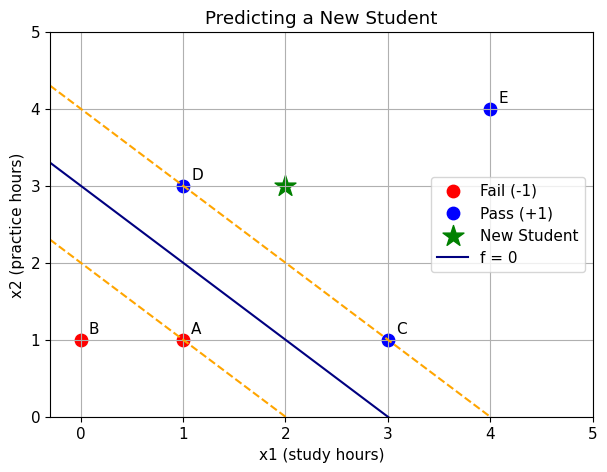

In [ ]:
#Check All Students and Predict a New Student
# Calculate scores for training data
scores = decision_function(X[:, 0], X[:, 1])

print("Training Results:\n")

for i in range(len(X)):
    predicted_class = 1 if scores[i] > 0 else -1

    result = "Pass" if predicted_class == 1 else "Fail"

    print(f"Student {names[i]}: f(x) = {scores[i]:.2f}"
          f" --> {result}")

# New student
new_student = np.array([2, 3])

new_score = decision_function(
    new_student[0], new_student[1]
)

prediction = 1 if new_score > 0 else -1

print("\nNew Student")
print("Study hours:", new_student[0])
print("Practice hours:", new_student[1])
print("Score:", new_score)

print("Prediction:",
      "Pass (+1)" if prediction == 1 else "Fail (-1)")

# Plot new student
plt.figure()

plt.scatter(X[y == -1, 0], X[y == -1, 1],
            color='red', label='Fail (-1)', s=80)

plt.scatter(X[y == 1, 0], X[y == 1, 1],
            color='blue', label='Pass (+1)', s=80)

plt.scatter(new_student[0], new_student[1],
            color='green', marker='*', s=250,
            label='New Student')

for i in range(len(X)):
    plt.text(X[i, 0] + 0.08, X[i, 1] + 0.08, names[i])

plt.plot(x1_line, line_0, color='navy', label='f = 0')
plt.plot(x1_line, line_minus, '--', color='orange')
plt.plot(x1_line, line_plus, '--', color='orange')

plt.xlabel('x1 (study hours)')
plt.ylabel('x2 (practice hours)')
plt.title('Predicting a New Student')

plt.xlim(-0.3, 5)
plt.ylim(0, 5)
plt.grid()
plt.legend()
plt.show()

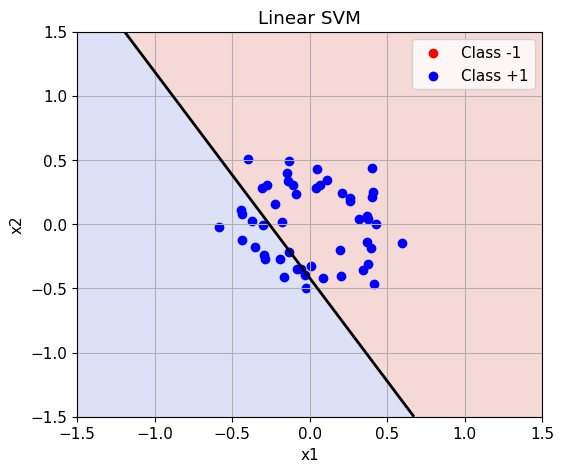

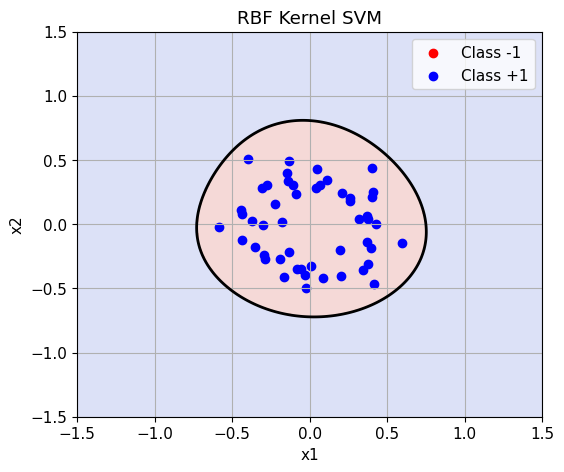

In [ ]:
# Why Do We Need a Kernel
#Generate circular data
X_circle, y_circle = make_circles(
    n_samples=100,
    factor=0.4,
    noise=0.08,
    random_state=42
)

# Linear SVM
linear_model = SVC(kernel='linear', C=10)
linear_model.fit(X_circle, y_circle)

# RBF Kernel SVM
rbf_model = SVC(kernel='rbf', C=10, gamma=2)
rbf_model.fit(X_circle, y_circle)


# Function to plot decision boundary
def plot_svm(model, title):

    x_min, x_max = -1.5, 1.5
    y_min, y_max = -1.5, 1.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(6, 5))

    plt.contourf(xx, yy, Z, alpha=0.2,
                 cmap='coolwarm')

    plt.scatter(X_circle[y_circle == -1, 0],
                X_circle[y_circle == -1, 1],
                color='red', label='Class -1')

    plt.scatter(X_circle[y_circle == 1, 0],
                X_circle[y_circle == 1, 1],
                color='blue', label='Class +1')

    plt.contour(xx, yy,
                model.decision_function(grid).reshape(xx.shape),
                levels=[0], colors='black', linewidths=2)

    plt.title(title)
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.grid()
    plt.legend()
    plt.show()


# Compare the two kernels
plot_svm(linear_model, 'Linear SVM')
plot_svm(rbf_model, 'RBF Kernel SVM')

In [ ]:
#Kernel Calculations
# Polynomial Kernel
x = np.array([1, 2])
z = np.array([2, 1])

d = 2

polynomial_value = (np.dot(x, z) + 1) ** d

print("Polynomial Kernel")
print("Dot product =", np.dot(x, z))
print("Kernel value =", polynomial_value)


# RBF Kernel
x = np.array([1, 2])
z = np.array([2, 2])

gamma = 0.5

distance_squared = np.sum((x - z) ** 2)

rbf_value = np.exp(-gamma * distance_squared)

print("\nRBF Kernel")
print("Squared distance =", distance_squared)
print("Gamma =", gamma)
print("Kernel value =", round(rbf_value, 3))

Polynomial Kernel
Dot product = 4
Kernel value = 25

RBF Kernel
Squared distance = 1
Gamma = 0.5
Kernel value = 0.607


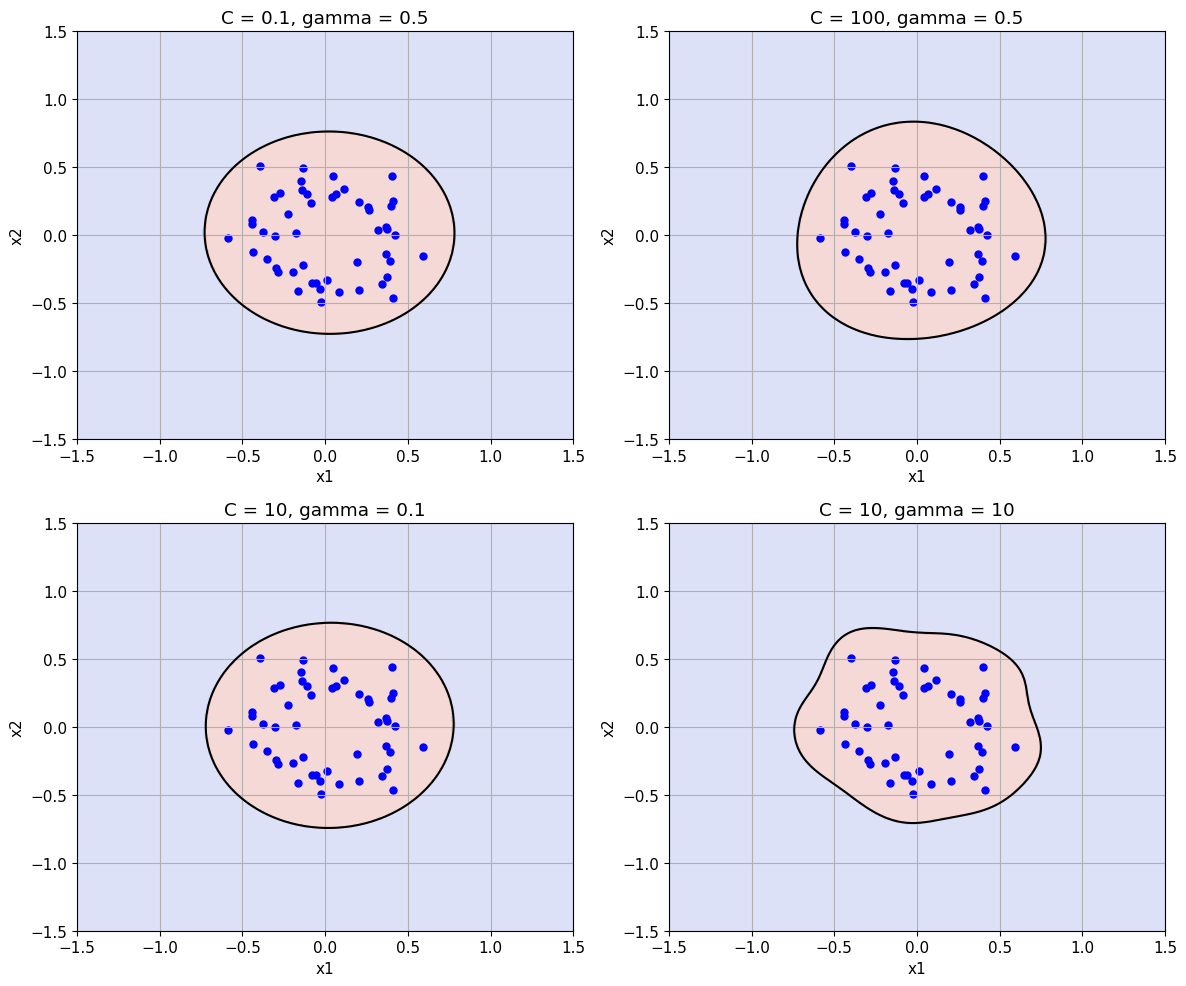

In [ ]:
#Effect of C and Gamma
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

settings = [
    ('C = 0.1, gamma = 0.5', 0.1, 0.5),
    ('C = 100, gamma = 0.5', 100, 0.5),
    ('C = 10, gamma = 0.1', 10, 0.1),
    ('C = 10, gamma = 10', 10, 10)
]

xx, yy = np.meshgrid(
    np.linspace(-1.5, 1.5, 250),
    np.linspace(-1.5, 1.5, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]

for ax, (title, C_value, gamma_value) in zip(
    axes.ravel(), settings
):

    model = SVC(kernel='rbf',
                C=C_value,
                gamma=gamma_value)

    model.fit(X_circle, y_circle)

    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z,
                alpha=0.2, cmap='coolwarm')

    ax.scatter(X_circle[y_circle == -1, 0],
               X_circle[y_circle == -1, 1],
               color='red', s=25)

    ax.scatter(X_circle[y_circle == 1, 0],
               X_circle[y_circle == 1, 1],
               color='blue', s=25)

    ax.contour(xx, yy,
               model.decision_function(grid).reshape(xx.shape),
               levels=[0], colors='black')

    ax.set_title(title)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.grid()

plt.tight_layout()
plt.show()

In [ ]:
# Soft Margin and Optimization
w = np.array([0.5, 0.5])

margin_cost = 0.5 * np.sum(w ** 2)

xi = np.array([0.3, 0, 0])

C = 10

penalty = C * np.sum(xi)

total_cost = margin_cost + penalty

print("Margin cost =", margin_cost)
print("Sum of xi =", np.sum(xi))
print("Penalty =", penalty)
print("Total cost =", total_cost)

Margin cost = 0.25
Sum of xi = 0.3
Penalty = 3.0
Total cost = 3.25
